# From gene identity to contextual functional organization

How does a frozen transcriptome model transform sample-invariant gene identity vectors into context-dependent gene representations, and does their functional geometry add signal beyond expression and coexpression?

We compare the static lookup table (L0) with contextual states at L1, L6, and L12. Quantitative neighborhood and prediction tests are distinguished from exploratory projections. Results concern known GO/KEGG annotations; they do not establish causal biological mechanisms.

In [1]:
from pathlib import Path
import hashlib, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from IPython.display import display

candidates = [Path.cwd(), Path.cwd() / 'benchmarks' / 'representation_analysis',
              Path.cwd() / 'representation_analysis']
REPORT = next((p.resolve() for p in candidates if (p / 'data' / 'provenance.json').is_file()), None)
if REPORT is None:
    raise FileNotFoundError('Run from the repository root, benchmarks/, or benchmarks/representation_analysis/')
DATA, FIGURES = REPORT / 'data', REPORT / 'figures'
FIGURES.mkdir(exist_ok=True)
FIGURE_DATA = DATA / 'figure_data'
FIGURE_DATA.mkdir(exist_ok=True)
provenance = json.loads((DATA / 'provenance.json').read_text())
validation = json.loads((DATA / 'validation.json').read_text())
assert validation['status'] == 'passed'
for record in provenance['cached_files']:
    path = DATA / record['file']
    assert hashlib.sha256(path.read_bytes()).hexdigest() == record['sha256'], record['file']
plt.rcParams.update({'font.size': 10, 'axes.spines.top': False, 'axes.spines.right': False,
                     'figure.dpi': 120, 'savefig.dpi': 250, 'pdf.fonttype': 42})
COHORT_COLORS = {'GTEx': '#237A8A', 'TCGA': '#BD5544'}
LAYERS = ['L0_static', 'L1_early', 'L6_middle', 'L12_final']
LABELS = ['L0', 'L1', 'L6', 'L12']
def save_figure(fig, stem, values):
    fig.savefig(FIGURES / f'{stem}.png', dpi=250, bbox_inches='tight')
    fig.savefig(FIGURES / f'{stem}.pdf', bbox_inches='tight')
    values.to_csv(FIGURE_DATA / f'{stem}.csv', index=False)
    plt.show()


## Data and methods

Bridge is frozen at checkpoint `r7hnr92k` (SHA256 `f3491beaa697a0408dc1daeb6f8d648566bd46bafc6e44938d723e7ffc325541`). Each gene has 512 features in the canonical 15,165-gene order. GTEx and TCGA use human GENCODE v49 exon-length TPM followed by natural `log1p`.

The balanced design contains 200 GTEx samples from 10 tissues and 200 TCGA samples from 10 tumor contexts, 20 samples per context. Normal tissues and tumors are unpaired; donor/study independence and sample-unseen pretraining status are not established. L0 is the same vector table for every sample; it is computed once rather than counted as 200 replicates. The larger static-expression color reference covers 25,370 cached human training samples, not the full 640,000 training samples.

GO Biological Process and KEGG annotation overlap is the functional endpoint. Enrichment uses the library-annotated canonical gene universe; overlapping terms are not independent biological measurements. The following sections distinguish within-sample gene neighborhoods, cohort-mean gene networks, and held-out-anchor pair prediction.

In [2]:
manifest = pd.read_csv(DATA / 'sample_manifest.csv')
assert len(manifest) == 400 and not manifest.duplicated(['dataset', 'sample_id']).any()
assert manifest.groupby(['dataset', 'context']).size().eq(20).all()
display(manifest.groupby(['dataset', 'context']).size().rename('Samples').reset_index())


,dataset,context,Samples
0,GTEx,cerebellum,20
1,GTEx,cortex,20
2,GTEx,heart,20
3,GTEx,liver,20
4,GTEx,lung,20
5,GTEx,pancreas,20
6,GTEx,skeletal muscle,20
7,GTEx,spleen,20
8,GTEx,subcutaneous adipose,20
9,GTEx,testis,20


## 1. Static gene identity: a weak functional geometry baseline

The lookup table is sample-invariant by architecture. PCA describes its gene-by-feature variance; clustering stability and neighborhood enrichment test whether a simple functional partition is evident. The exploratory characterization compares raw, L2-normalized, and post-hoc LayerNorm vectors (primary k=10; seeds 42/43/44; three K-means initializations; 10 annotation nulls and one vector-shuffle null).

Near-full dimensionality, near-zero silhouette, and very low ARI indicate weak stable spherical partitions under these settings. They do not imply that static vectors contain no decodable information. The saved t-SNE coordinates were generated after PCA-50 and are used only as a descriptive illustration; mean training TPM is a color annotation.

,representation,pca_participation_ratio,pcs_for_90pct,silhouette,cluster_stability_ari,significant_go_terms,significant_kegg_terms
0,raw,495.091388,443,-0.000276,0.006185,0,0
1,l2_cosine,495.143555,443,0.000048,0.004547,0,4
2,layernorm,494.210990,442,-0.000048,0.005769,2,0


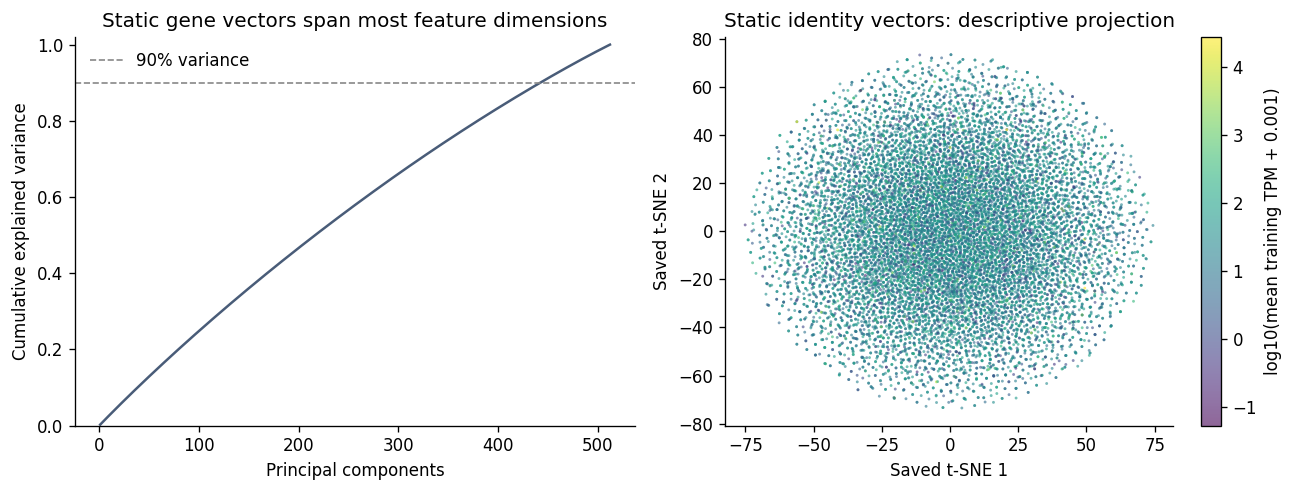

In [3]:
static = pd.read_csv(DATA / 'static_geometry.csv')
pca = pd.read_csv(DATA / 'static_pca_variance.csv')
coords = pd.read_csv(DATA / 'static_gene_coordinates.csv')
assert len(coords) == 15165 and coords.gene.is_unique
assert list(coords.token_id) == list(range(1, 15166))
display(static[['representation','pca_participation_ratio','pcs_for_90pct','silhouette',
                'cluster_stability_ari','significant_go_terms','significant_kegg_terms']].round(6))
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
axes[0].plot(pca.pc, pca.cumulative_explained_variance, color='#495C78')
axes[0].axhline(.9, color='#888', ls='--', lw=1, label='90% variance')
axes[0].set(xlabel='Principal components', ylabel='Cumulative explained variance',
            title='Static gene vectors span most feature dimensions', ylim=(0,1.02))
axes[0].legend(frameon=False)
scatter = axes[1].scatter(coords.tsne_1, coords.tsne_2, c=coords.log10_average_training_tpm,
                          s=3, alpha=.6, cmap='viridis', linewidths=0, rasterized=True)
fig.colorbar(scatter, ax=axes[1], label='log10(mean training TPM + 0.001)')
axes[1].set(xlabel='Saved t-SNE 1', ylabel='Saved t-SNE 2', title='Static identity vectors: descriptive projection')
fig.tight_layout()
save_figure(fig, 'static_identity_geometry', coords)
pca.to_csv(FIGURE_DATA / 'static_pca_variance.csv', index=False)


## 2. Functional neighborhoods across sampled depths

Neighbors are other genes within the same sample, excluding self-neighbors. The primary display uses mean-centered cosine at k=25 and shared GO/KEGG annotation among eligible query-neighbor pairs relative to random-neighbor overlap. These per-sample analyses use 10 null repetitions and are exploratory; k=10/50 and raw-cosine results are retained in the numerical tables.

Error bars show **sample SD across 200 samples**, not confidence intervals or seed variation. L0 has n=1 and no replicate SD. Increasing functional enrichment across these sampled layers is quantitative evidence; the depth comparison does not inspect every intermediate layer or isolate a causal processing mechanism.

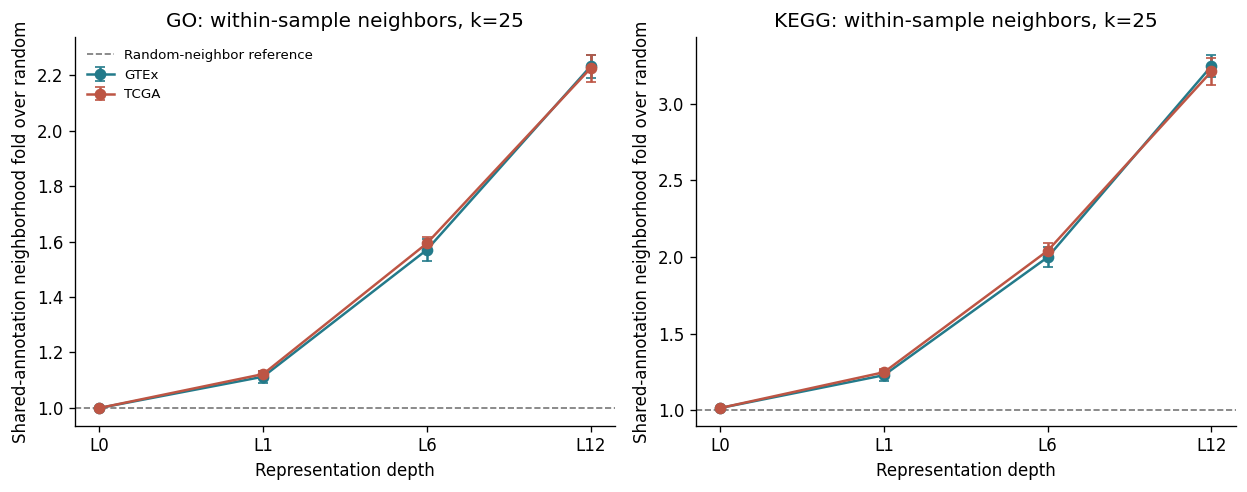

,dataset,library,layer,neighbor_fold,neighbor_fold_sd,samples_x
1,GTEx,GO,L0_static,0.999189,NaN,1
4,GTEx,KEGG,L0_static,1.014300,NaN,1
13,GTEx,GO,L12_final,2.231805,0.042576,200
16,GTEx,KEGG,L12_final,3.246897,0.074153,200
25,GTEx,GO,L1_early,1.112140,0.021664,200
28,GTEx,KEGG,L1_early,1.228650,0.035797,200
37,GTEx,GO,L6_middle,1.569937,0.039825,200
40,GTEx,KEGG,L6_middle,1.999080,0.063488,200
49,TCGA,GO,L0_static,0.999189,NaN,1
52,TCGA,KEGG,L0_static,1.014300,NaN,1


In [4]:
depth = pd.read_csv(DATA / 'depth_summary.csv')
samples = pd.read_csv(DATA / 'depth_per_sample.csv')
for row in depth.itertuples():
    q = samples[(samples.dataset == row.dataset) & (samples.layer == row.layer) &
                (samples.geometry == row.geometry) & (samples.library == row.library) & (samples.k == row.k)]
    assert len(q) == row.samples_x
    assert np.isclose(q.neighbor_fold.mean(), row.neighbor_fold, atol=1e-12, rtol=0)
    if len(q) > 1:
        assert np.isclose(q.neighbor_fold.std(ddof=1), row.neighbor_fold_sd, atol=1e-12, rtol=0)
primary_depth = depth.query("k == 25 and geometry == 'mean_centered_cosine'").copy()
fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.2), sharex=True)
for ax, library in zip(axes, ['GO','KEGG']):
    for dataset in ['GTEx','TCGA']:
        q = primary_depth[(primary_depth.dataset == dataset) & (primary_depth.library == library)].set_index('layer').loc[LAYERS]
        ax.errorbar(np.arange(4), q.neighbor_fold, yerr=q.neighbor_fold_sd.fillna(0), marker='o',
                    capsize=3, color=COHORT_COLORS[dataset], label=dataset)
    ax.axhline(1, color='#777', ls='--', lw=1, label='Random-neighbor reference')
    ax.set(xticks=range(4), xticklabels=LABELS, xlabel='Representation depth',
           ylabel='Shared-annotation neighborhood fold over random', title=f'{library}: within-sample neighbors, k=25')
axes[0].legend(frameon=False, fontsize=8)
fig.tight_layout()
save_figure(fig, 'functional_depth', primary_depth)
display(primary_depth[['dataset','library','layer','neighbor_fold','neighbor_fold_sd','samples_x']].round(6))


### Context-colored gene shifts

For 500 fixed genes, two representative samples per tissue/tumor context were averaged. Each gene's mean across contexts was subtracted within cohort/layer before the original joint PCA-50/UMAP projection. L0 residuals are exactly zero by construction. Here only the saved coordinates are redrawn.

Each colored point is a gene in a context; colors identify tissues or tumor cohorts, not inferred clusters. Coordinate axes differ by layer, and visual separation is not an effect size. Context residualization intentionally emphasizes context variation; the quantitative tests above and below support the interpretation.

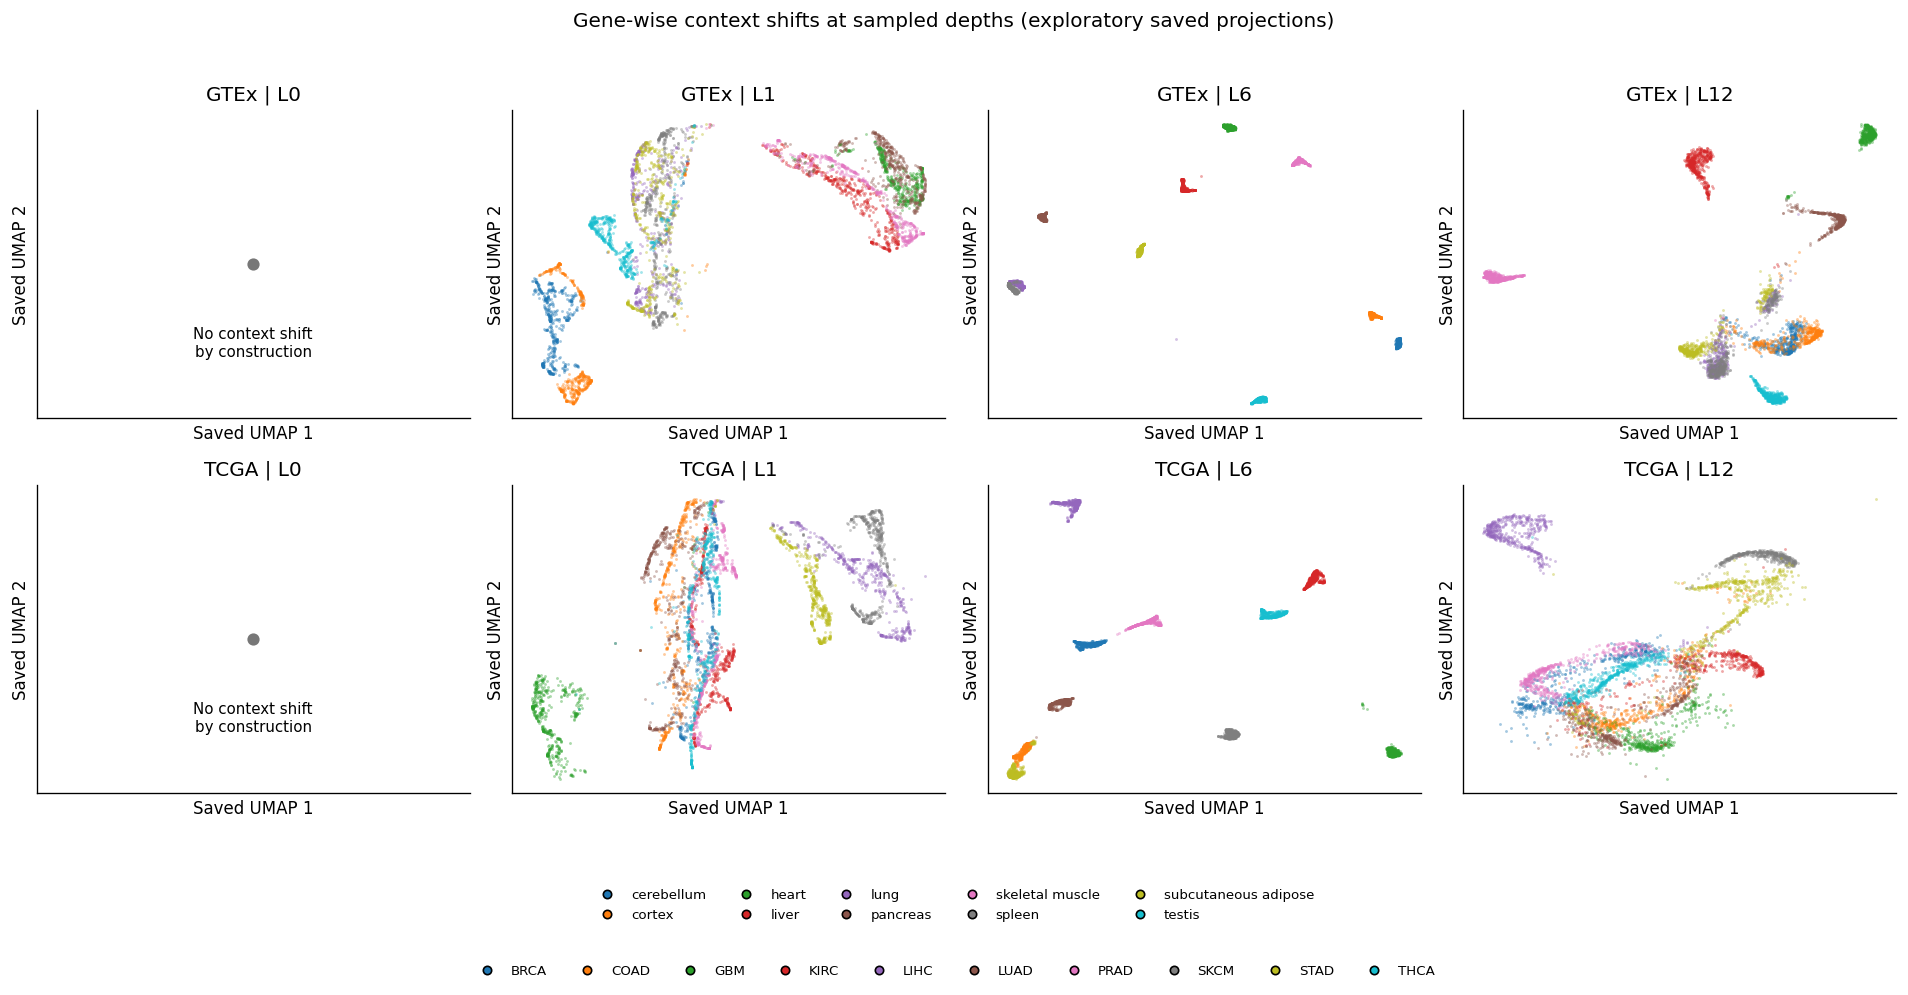

In [5]:
projection = pd.read_csv(DATA / 'context_umap_coordinates.csv')
assert len(projection) == 40000
fig, axes = plt.subplots(2, 4, figsize=(16, 7.8))
legend_rows = {}
for row, dataset in enumerate(['GTEx','TCGA']):
    contexts = sorted(projection[projection.dataset == dataset].context.unique())
    palette = {name: plt.get_cmap('tab10')(i) for i,name in enumerate(contexts)}
    for column, layer in enumerate(LAYERS):
        ax = axes[row,column]
        q = projection[(projection.dataset == dataset) & (projection.layer == layer)]
        assert len(q) == 5000 and q.gene.nunique() == 500
        if layer == 'L0_static':
            assert np.allclose(q[['umap_1','umap_2']], 0)
            ax.scatter([0],[0], s=40, color='#777')
            ax.text(.5,.2,'No context shift\nby construction', transform=ax.transAxes, ha='center', fontsize=9)
        else:
            for context in contexts:
                part = q[q.context == context]
                ax.scatter(part.umap_1, part.umap_2, color=palette[context], s=3, alpha=.4,
                           linewidths=0, rasterized=True)
        ax.set(title=f'{dataset} | {LABELS[column]}', xlabel='Saved UMAP 1', ylabel='Saved UMAP 2')
        ax.set_xticks([]); ax.set_yticks([])
    legend_rows[dataset] = [Line2D([0],[0],marker='o',color='none',markerfacecolor=palette[name],
                                  markersize=5,label=name) for name in contexts]
fig.legend(handles=legend_rows['GTEx'], loc='lower center', bbox_to_anchor=(.5,.025), ncol=5, frameon=False, fontsize=8)
fig.legend(handles=legend_rows['TCGA'], loc='lower center', bbox_to_anchor=(.5,-.035), ncol=10, frameon=False, fontsize=8)
fig.suptitle('Gene-wise context shifts at sampled depths (exploratory saved projections)', y=1.01)
fig.tight_layout(rect=[0,.13,1,.99])
save_figure(fig, 'context_shifts_umap', projection)


## 3. Within-context heterogeneity and between-context differentiation

For the same gene, compare mean cosine between samples within a context and across different contexts. Lower within-context cosine indicates less consistent **direction**, rather than larger absolute embedding variance. The within-minus-across difference measures context differentiation.

At L12, TCGA has lower within-context consistency than GTEx, while GTEx has greater between-context differentiation. The two observations should not be condensed into an unqualified claim that TCGA is simply more variable. The tiny L0 difference is numerical noise. These cohort differences are descriptive and do not estimate a paired cancer effect; no biological-replicate confidence intervals were computed for this summary.

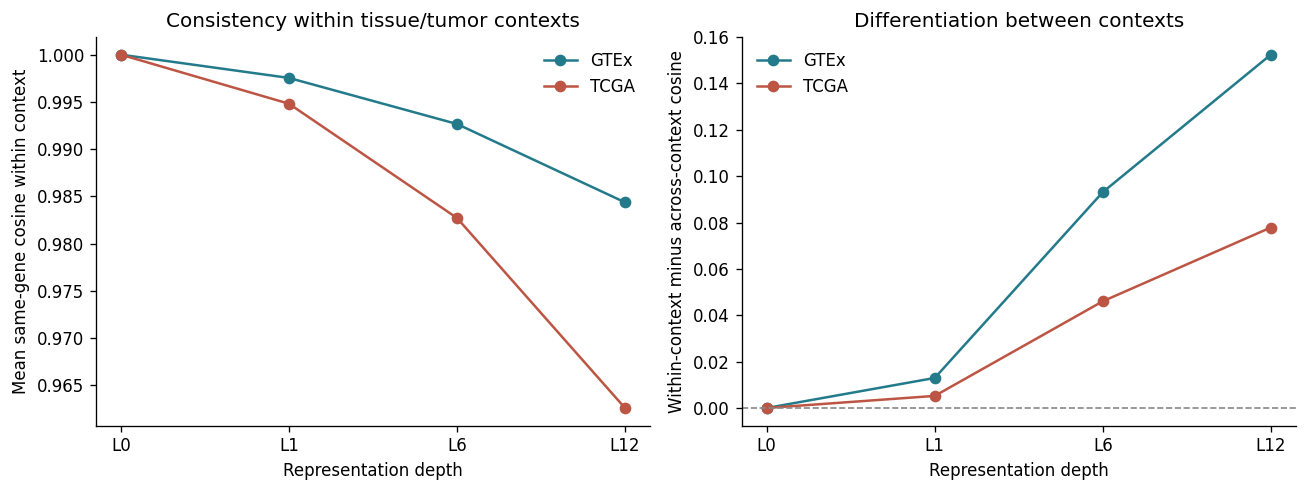

,dataset,layer,within_context_cosine,across_context_cosine,within_minus_across,genes_positive_difference
3,GTEx,L12_final,0.984363,0.831963,0.15240,1.0
7,TCGA,L12_final,0.962585,0.884735,0.07785,1.0


In [6]:
context = pd.read_csv(DATA / 'context_dependence.csv')
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for dataset in ['GTEx','TCGA']:
    q = context[context.dataset == dataset].set_index('layer').loc[LAYERS]
    axes[0].plot(range(4), q.within_context_cosine, marker='o', color=COHORT_COLORS[dataset], label=dataset)
    axes[1].plot(range(4), q.within_minus_across, marker='o', color=COHORT_COLORS[dataset], label=dataset)
axes[0].set(ylabel='Mean same-gene cosine within context', title='Consistency within tissue/tumor contexts')
axes[1].set(ylabel='Within-context minus across-context cosine', title='Differentiation between contexts')
axes[1].axhline(0, color='#888', ls='--', lw=1)
for ax in axes:
    ax.set(xticks=range(4), xticklabels=LABELS, xlabel='Representation depth')
    ax.legend(frameon=False)
fig.tight_layout()
save_figure(fig, 'within_between_context', context)
display(context.query("layer == 'L12_final'").round(6))


## 4. Does L12 exceed ordinary coexpression?

Pearson and Spearman networks are computed across the same 200 samples per cohort; Bridge uses cohort-mean gene vectors and mean-centered cosine. This **cohort-level** endpoint is distinct from within-sample neighborhoods. Every method excludes genes constant in its cohort: 15,037 eligible GTEx genes and 15,105 eligible TCGA genes.

Functional enrichment is the aggregate shared-term query-neighbor fraction divided by the mean of 100 random-neighbor matrices. Error bars are 95% percentile intervals from 1,000 gene bootstraps with a drawn null replicate. These intervals do not quantify new-cohort reproducibility or form a paired significance test of method differences. L12/best-coexpression ratios are descriptive enrichment comparisons, not information-retention percentages.

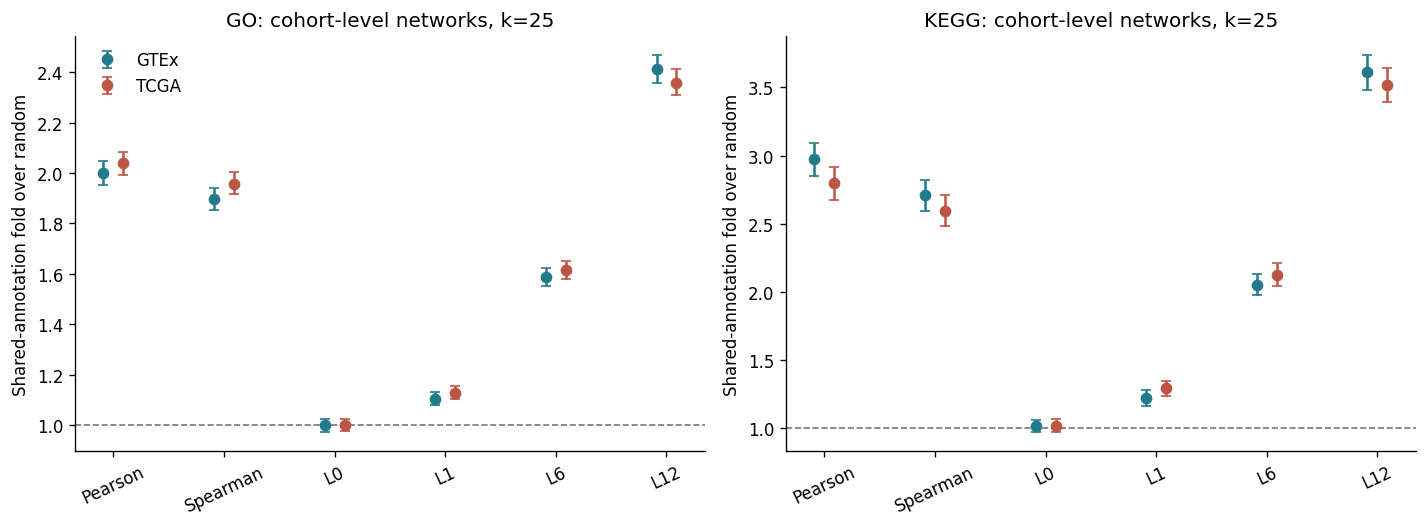

,dataset,library,Bridge L0,Bridge L1,Bridge L12,Bridge L6,Pearson,Spearman,L12_minus_best_coexpression,L12_over_best_coexpression
0,GTEx,GO,0.997778,1.104341,2.412293,1.587750,2.000311,1.895352,0.411982,1.205959
1,GTEx,KEGG,1.018083,1.220618,3.611873,2.048157,2.973288,2.708346,0.638584,1.214774
2,TCGA,GO,0.999253,1.128382,2.359160,1.613033,2.038381,1.958283,0.320779,1.157370
3,TCGA,KEGG,1.018209,1.294499,3.514779,2.127461,2.795839,2.596860,0.718939,1.257146


In [7]:
coex = pd.read_csv(DATA / 'coexpression_comparison.csv')
assert np.allclose(coex.observed_rate / coex.null_mean, coex.fold_over_null, atol=1e-12)
primary_coex = coex[coex.k == 25].copy()
methods = ['Pearson','Spearman','Bridge L0','Bridge L1','Bridge L6','Bridge L12']
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, library in zip(axes, ['GO','KEGG']):
    for offset, dataset in [(-.09,'GTEx'),(.09,'TCGA')]:
        q = primary_coex[(primary_coex.dataset == dataset) & (primary_coex.library == library)].set_index('method').loc[methods]
        ax.errorbar(np.arange(6)+offset, q.fold_over_null,
                    yerr=np.vstack([q.fold_over_null-q.ci_low, q.ci_high-q.fold_over_null]),
                    fmt='o', capsize=3, color=COHORT_COLORS[dataset], label=dataset)
    ax.axhline(1, color='#777', ls='--', lw=1)
    ax.set(xticks=range(6), xticklabels=['Pearson','Spearman','L0','L1','L6','L12'],
           ylabel='Shared-annotation fold over random', title=f'{library}: cohort-level networks, k=25')
    ax.tick_params(axis='x', rotation=25)
axes[0].legend(frameon=False)
fig.tight_layout()
save_figure(fig, 'matched_coexpression', primary_coex)
display(pd.read_csv(DATA / 'coexpression_primary_k25.csv').round(6))


## 5. Incremental prediction after expression controls

The binary outcome is whether two annotated genes share a GO term or KEGG pathway. The **base** logistic model contains Pearson, Spearman, pair-average mean `log1p(TPM)`, and absolute mean-expression difference. The **full** model adds L12 cosine. Five-fold anchor-gene GroupKFold uses within-fold standardization and logistic regression (C=10,000); confidence intervals use 500 anchor-gene bootstrap replicates. AP denotes average precision, whose reference depends on class prevalence.

Anchor groups are held out, but partner genes can recur across folds: this is **not fully gene-disjoint evaluation**. Partners were sampled with replacement, producing 722 repeated directed GO rows and 198 repeated directed KEGG rows per cohort. Counts refer to sampled rows, not distinct pairs; the frozen analysis retains their sampling weights. Repeated directed pairs share an anchor group. Representations and correlation networks summarize the complete expression cohort; the target is gene-pair annotation, not future patient outcomes. The following values were recalculated from saved out-of-fold predictions; no models or bootstrap intervals were refitted.

The modest positive increments support added predictive signal beyond the specified covariates. They do not rule out nonlinear expression effects or establish expression-independent biology.

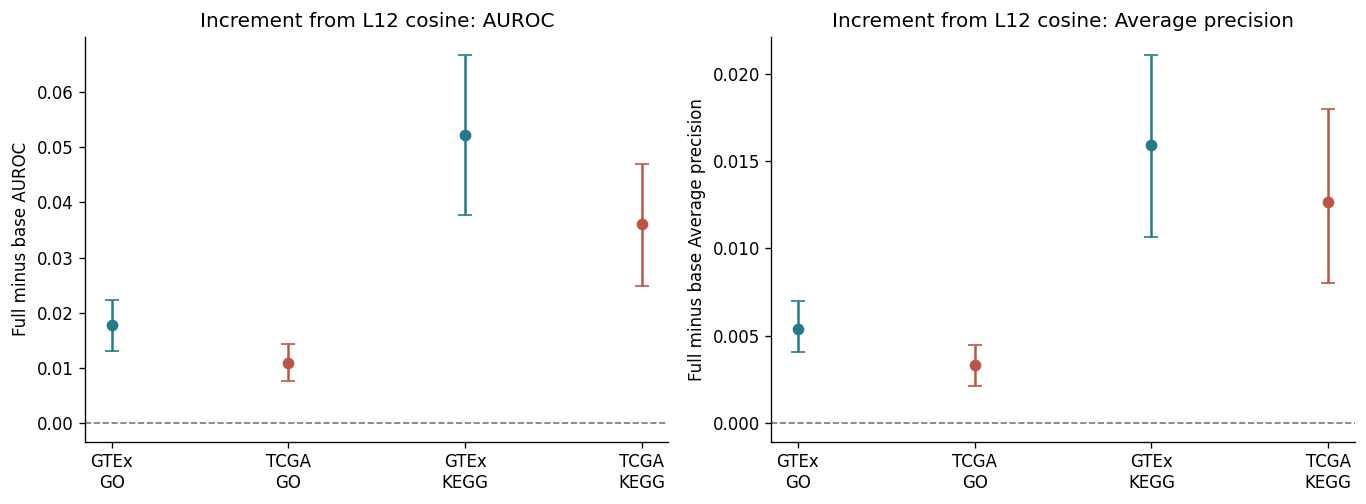

,dataset,library,pairs,positive_pairs,negative_pairs,anchor_genes,base_auroc,full_auroc,delta_auroc,delta_auroc_ci_low,delta_auroc_ci_high,base_auprc,full_auprc,delta_auprc
0,GTEx,GO,211187,14802,196385,2511,0.555027,0.572767,0.017740,0.013142,0.022254,0.086165,0.091576,0.005411
1,GTEx,KEGG,56416,2986,53430,1290,0.532900,0.585089,0.052189,0.037672,0.066615,0.063526,0.079466,0.015940
2,TCGA,GO,211187,14802,196385,2511,0.568405,0.579228,0.010824,0.007573,0.014392,0.090437,0.093743,0.003306
3,TCGA,KEGG,56416,2986,53430,1290,0.556894,0.592913,0.036019,0.024851,0.046874,0.067771,0.080419,0.012648


In [8]:
conditional = pd.read_csv(DATA / 'conditional_results.csv')
recalculated = pd.read_csv(DATA / 'recomputed_prediction_metrics.csv')
check = conditional.merge(recalculated, on=['dataset','library'], validate='one_to_one', suffixes=('_saved','_recomputed'))
for key in ['base_auroc','full_auroc','base_auprc','full_auprc']:
    assert np.allclose(check[key+'_saved'], check[key+'_recomputed'], atol=1e-12, rtol=0)
conditional['negative_pairs'] = conditional.pairs - conditional.positive_pairs
order = [('GTEx','GO'),('TCGA','GO'),('GTEx','KEGG'),('TCGA','KEGG')]
q = conditional.set_index(['dataset','library']).loc[order].reset_index()
fig, axes = plt.subplots(1,2,figsize=(11.5,4.3))
for ax, metric, label in [(axes[0],'auroc','AUROC'),(axes[1],'auprc','Average precision')]:
    for i,row in enumerate(q.itertuples()):
        value = getattr(row,'delta_'+metric)
        low,high = getattr(row,'delta_'+metric+'_ci_low'),getattr(row,'delta_'+metric+'_ci_high')
        ax.errorbar(i,value,yerr=[[value-low],[high-value]],fmt='o',capsize=4,color=COHORT_COLORS[row.dataset])
    ax.axhline(0,color='#777',ls='--',lw=1)
    ax.set(xticks=range(4),xticklabels=[f'{d}\n{lib}' for d,lib in order],
           ylabel=f'Full minus base {label}', title=f'Increment from L12 cosine: {label}')
fig.tight_layout()
save_figure(fig, 'conditional_predictive_gain', conditional)
display(conditional[['dataset','library','pairs','positive_pairs','negative_pairs','anchor_genes',
                     'base_auroc','full_auroc','delta_auroc','delta_auroc_ci_low','delta_auroc_ci_high',
                     'base_auprc','full_auprc','delta_auprc']].round(6))


## 6. Functional modules after linear expression residualization

Cohort-mean gene vectors were clustered with Euclidean K-means (k=10, five seeds 42–46, 10 initializations). A control subtracts each feature's least-squares linear association with cohort mean expression before reclustering. Separate expression-decile modules provide an expression-only reference. GO/KEGG over-representation uses one-sided hypergeometric tests and BH correction within cluster/library.

Bars count significant **cluster–term rows**; terms can recur across clusters and share genes. Persistence after linear residualization shows that simple mean-expression structure is incomplete as an explanation. Neither the counts nor residual/original ratios measure the fraction of biological information retained; linear adjustment does not remove all expression effects.

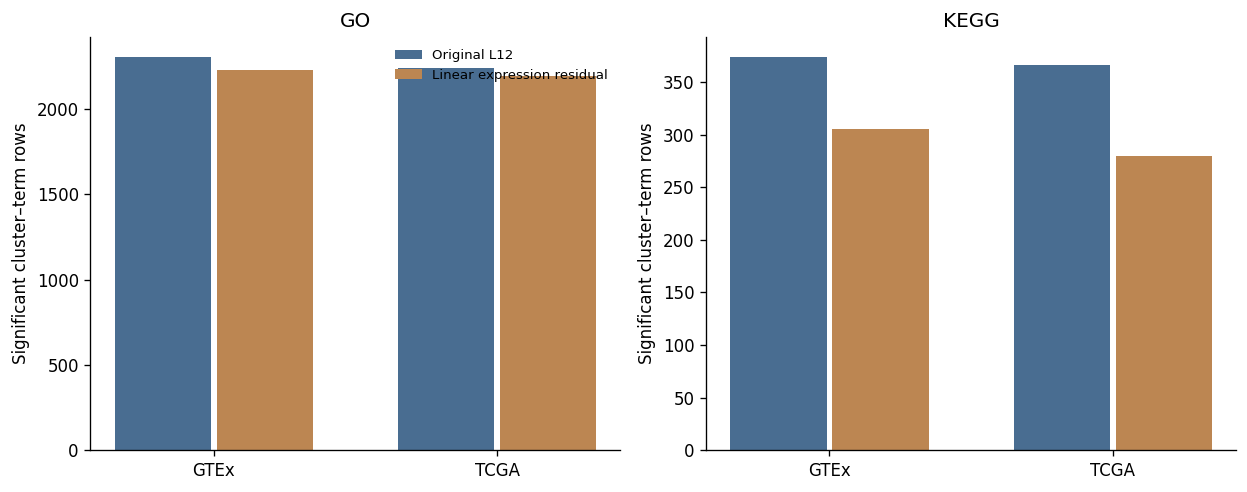

,dataset,control,significant_go_terms,significant_kegg_terms,layer,silhouette,stability_ari
0,GTEx,expression_deciles,382,73,NaN,NaN,NaN
4,GTEx,linear_tpm_residual,2229,305,L12_final,0.019278,0.926587
5,TCGA,expression_deciles,493,98,NaN,NaN,NaN
9,TCGA,linear_tpm_residual,2192,280,L12_final,0.016037,0.858743


In [9]:
modules = pd.read_csv(DATA / 'module_summary.csv')
controls = pd.read_csv(DATA / 'expression_control_summary.csv')
original = modules.query("layer == 'L12_final'").set_index('dataset')
residual = controls.query("layer == 'L12_final' and control == 'linear_tpm_residual'").set_index('dataset')
fig, axes = plt.subplots(1,2,figsize=(10.5,4.2))
rows=[]
for ax, library in zip(axes,['go','kegg']):
    key='significant_'+library+'_terms'
    for offset, label, frame, color in [(-.18,'Original L12',original,'#496D91'),(.18,'Linear expression residual',residual,'#BC8652')]:
        vals=frame.loc[['GTEx','TCGA'],key]
        ax.bar(np.arange(2)+offset,vals,width=.34,label=label,color=color)
        for dataset,value in vals.items():rows.append({'dataset':dataset,'library':library.upper(),'condition':label,'significant_cluster_term_rows':value})
    ax.set(xticks=range(2),xticklabels=['GTEx','TCGA'],ylabel='Significant cluster–term rows',title=library.upper())
axes[0].legend(frameon=False,fontsize=8)
fig.tight_layout()
save_figure(fig,'expression_residual_modules',pd.DataFrame(rows))
display(controls[controls.control.eq('expression_deciles') | controls.layer.eq('L12_final')].round(6))


## Limitations and conclusion

- Related cohorts, annotation libraries, geometries, and k values were explored across several stages; these are not independent confirmatory studies or a preregistered endpoint selection.
- Partner sampling includes repeated directed pair rows; counts are not counts of unique interactions. Annotation overlap is not an independent biological phenotype. Gene/partner reuse, annotation degree, and overlapping terms create dependence; anchor grouping addresses only part of it.
- Early screens have few null repetitions. Later gene/anchor-bootstrap intervals describe their chosen resampling units, not donor/study replication or generalization to unseen studies.
- Pretraining exposure and donor independence have not been established here; GTEx and TCGA are unpaired. Context variation does not establish a cancer mechanism.
- Clustering stability, small silhouettes, and exploratory UMAPs require restrained interpretation; L12 is not uniformly the most visually separated layer.

**Conclusion:** across the sampled depths, functional neighborhoods become stronger than the static identity baseline. Gene states reflect context in two distinct ways—within-context heterogeneity and between-context differentiation. Matched coexpression, linear expression controls, and modest held-out-anchor predictive improvements support functional signal beyond the tested simple baselines, without establishing causal or expression-independent biology.

In [10]:
assert validation['prediction_rows_checked'] == 535206
assert validation['depth_groups_checked'] == 96
assert validation['maximum_metric_difference'] <= validation['absolute_metric_tolerance']
print('Cohort, saved-result, and numerical verification checks passed.')

Cohort, saved-result, and numerical verification checks passed.
